## **Building a Data Scientist AI Agent in CrewAI**
### **Project Overview**
### In this project, we will apply machine learning regession techniques to predict revenue generated from supplement sales (Unit Sold) based on various factors such as price, location, and discounts.
### We will focus on understanding the workflow to build machine learning regression models in a typical data science project, to automate it using AI agents built in CrewAI.

## Model Inputs: Date, Product Name, Category, Price, Discount, Location
#                |
### Machine Learning Regression Model, CrewAI (AI Agent Framework)
#                |
### Model Output: to predict Units Sold


# What is CrewAI?
### CrewAI is an open source Python framework designed to build and manage multi-agent AI systems.
### It enables the developers to create teams of AI agents named "Crew"
### These crews colaborate to execute complex, multi-step tasks more efficiently than a single agent could manage alone. Each agent within a crew is assigned a specific role, goal, and set of tools, facilitating structured  and autonomous workflows.
### Just like a company has (Sales, Engineering, marketing), working together under a leadership to acieve business goals.
### CrewAI helps you create an organization of AI agents with specialized roles collaborating to accomplish complex tasks.


## **Key Learning Objectives**
### 1. Understand CrewAI core components, Agents, Tasks, Tools, and the crew.
### 2. Create a custom tool that allows our agent to execute Python coder (for data analysis and modelling).
### 3. Designed specialized agents for:
### a. planning data science workflow
### b. executing data analysis / modelling.
### c. building / evaluating model.
### 4. Review machine learning regression fundamentals and perform the entire workflow mannually (without CrewAI)
### 5. Assemble a crew of AI agents to perform the regression analysis on the supplement sales data.
### 6. Examine the results generated by the CrewAI agents, including the final analysis and the code produced, and compare its manual results.

# **Predictive Analytics with Machine Learning (Manual)**
## **Steps:**
### 1. Load and inspect the supplement sales dataset (Supplement_Sales_Weekly_Expanded)
### 2. Handle Missing Values (Demonstrate imputation techniques)
### 3. Perform Exploratory Data Analysis (EDA) to understand the data's structure, distributions, and relationshops using statistics and visualizations.
### 4. Preprocess the data. Clean the data. Handle categorical features (like product, category, location), and split the data for model training and testing.
### 5. Build and train a Linear Regression Model. Our first simple regression model.
### 6. Build and train Random Forest Regression model. Amore complex, tree-based ensemble model.
### Evaluate both models using standard regression metrics (like R-Squared. MAE, MSE) and compare their performance.


## Understanding the Fundamentals of Machine Learning Regression.
### 1. Machine Learning Regression focuses on predicting continuous numerical values.
### 2. In business, understanding the factors that drive revenue is critical for strategic growth.
### 3. By developing regression models, businesses can:
### a. identify key drivers of sales (e.g, which product category sells best, impact of discounts).
### b. potentially forecast future revenue based on planned promotions or product launches.
### c. gain insights into customer behaviour across different locations and platforms.

In [ ]:
# Let's install Matplotlib, Scikit-learn and Seaborn
!pip install matplotlib
!pip install scikit-learn
!pip install seaborn

In [ ]:
# Import Necessary Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer    # Added for missing values
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import warnings    # Added to ignore potential warnings during visualizatio or modelling

# Configure settings for better visualization
sns.set_style('whitegrid')      # Set a nice default style for seaborn.
plt.rcParams['figure.figsize'] = (10, 6)    # Set default figure size for matplotlib plots.
warnings.filterwarnings('ignore')     # Ignore general warnings for cleaner output.

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [ ]:
# Load the dataset from the csv and store it in a Pandas Dataframe tittled "df"
data = pd.read_csv("/content/drive/MyDrive/Supplement data/Supplement_Sales_Weekly_Expanded.csv")

In [ ]:
data.head()

,Date,Product Name,Category,Units Sold,Price,Revenue,Discount,Units Returned,Location,Platform
0,2020-01-06,Whey Protein,Protein,143,31.98,4573.14,0.03,2,Canada,Walmart
1,2020-01-06,Vitamin C,Vitamin,139,42.51,5908.89,0.04,0,UK,Amazon
2,2020-01-06,Fish Oil,Omega,161,12.91,2078.51,0.25,0,Canada,Amazon
3,2020-01-06,Multivitamin,Vitamin,140,16.07,2249.80,0.08,0,Canada,Walmart
4,2020-01-06,Pre-Workout,Performance,157,35.47,5568.79,0.25,3,Canada,iHerb


In [ ]:
# Let's display no of Rows and Columns
data.shape

(4384, 10)

In [ ]:
# Displa the last 5 Rows
data.tail(5)

,Date,Product Name,Category,Units Sold,Price,Revenue,Discount,Units Returned,Location,Platform
4379,2025-03-31,Melatonin,Sleep Aid,160,47.79,7646.40,0.21,1,USA,iHerb
4380,2025-03-31,Biotin,Vitamin,154,38.12,5870.48,0.22,1,UK,Walmart
4381,2025-03-31,Green Tea Extract,Fat Burner,139,20.40,2835.60,0.12,3,USA,iHerb
4382,2025-03-31,Iron Supplement,Mineral,154,18.31,2819.74,0.23,2,Canada,Amazon
4383,2025-03-31,Electrolyte Powder,Hydration,178,39.12,6963.36,0.23,0,UK,iHerb


In [ ]:
# Display concise summary (non-null, counts, datatypes)
print("\nDataset Information:")
data.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4384 entries, 0 to 4383
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Date            4384 non-null   object 
 1   Product Name    4384 non-null   object 
 2   Category        4384 non-null   object 
 3   Units Sold      4384 non-null   int64  
 4   Price           4384 non-null   float64
 5   Revenue         4384 non-null   float64
 6   Discount        4384 non-null   float64
 7   Units Returned  4384 non-null   int64  
 8   Location        4384 non-null   object 
 9   Platform        4384 non-null   object 
dtypes: float64(3), int64(2), object(5)
memory usage: 342.6+ KB


In [ ]:
# Display descriptive statistics for numerical columns
print("\nDescriptive Statistics (Numerical Columns):")
display(data.describe())


Descriptive Statistics (Numerical Columns):


,Units Sold,Price,Revenue,Discount,Units Returned
count,4384.000000,4384.000000,4384.000000,4384.000000,4384.000000
mean,150.200274,34.781229,5226.569446,0.124398,1.531478
std,12.396099,14.198309,2192.491946,0.071792,1.258479
min,103.000000,10.000000,1284.000000,0.000000,0.000000
25%,142.000000,22.597500,3349.372500,0.060000,1.000000
50%,150.000000,34.720000,5173.140000,0.120000,1.000000
75%,158.000000,46.712500,7009.960000,0.190000,2.000000
max,194.000000,59.970000,10761.850000,0.250000,8.000000


In [ ]:
# Display descriptive statistics for categorical columns
print("\nDescriptive Statistics (Categorical Columns):")
display(data.describe(include = ["object"]))


Descriptive Statistics (Categorical Columns):


,Date,Product Name,Category,Location,Platform
count,4384,4384,4384,4384,4384
unique,274,16,10,3,3
top,2025-03-31,Whey Protein,Vitamin,Canada,iHerb
freq,16,274,822,1507,1499


In [ ]:
# Locate the missing values in the Pandas DataFrame
missing_values = data.isnull().sum()
print("\nMissing Values in Each Column:")
print(missing_values)


Missing Values in Each Column:
Date              0
Product Name      0
Category          0
Units Sold        0
Price             0
Revenue           0
Discount          0
Units Returned    0
Location          0
Platform          0
dtype: int64


In [ ]:
# Unique Location
data["Location"].unique()

array(['Canada', 'UK', 'USA'], dtype=object)

In [ ]:
# Unique Platform
data["Platform"].unique()

array(['Walmart', 'Amazon', 'iHerb'], dtype=object)

In [ ]:
# Unique Product Name and Number of Product Name
print(data["Product Name"].nunique())
print(data["Product Name"].unique())

16
['Whey Protein' 'Vitamin C' 'Fish Oil' 'Multivitamin' 'Pre-Workout' 'BCAA'
 'Creatine' 'Zinc' 'Collagen Peptides' 'Magnesium' 'Ashwagandha'
 'Melatonin' 'Biotin' 'Green Tea Extract' 'Iron Supplement'
 'Electrolyte Powder']


### **Handling Missing Values**

### Imputation:
### Replace missing values with estimated or calculated values. Common imputation techniques include:
### 1. Mean Imputation: Replace missng numerical values with the mean of the column. Sensitive to outliers.
### 2. Median Imputation: Replace missing numerical values with the median of the column. More robust to outliers than mean.
### 3. Mode Imputation: Replace missing categorical values with the mode of (most frequent value) of the column.

### -Identify columns with missing values
### cols_with_missing_values = ["Price", "Discount"]

### -Initialize the SimpleImputer with the "median" strategy
### median_imputer = SimpleImputer(strategy = "median")

### -Apply the imputer to the selected columns
### .fit_transform() calculates the median and replaces NaNs in one step.
### -It returns numpy arrays, so we need to put it back into the DataFrame.
###  data[clos_with_missing_values] = median_imputer.fit_transform(data[cols_with_missing_values])
### print("\nMissing values after Median Imputation:")
### print(data.isnull().sum())

### if data[cols_with_missing_values].isnull().sum() == 0:
###      print("\nMissing values in "Price" and "Discount" Successfully imputed.")
### else:
###     print("\nWarning: Missing values still detected after imputation attempt")


### -Let's read the raw dataset again and drop any row containing missing values.
### file_path = "supplement_sales_weekly.csv"
### data_practice_opportunity = pd.read_csv(file_path)
### print(f"Rows before dropping: {data_practice_opportunity.shape[0]}")


### -Let's drop the rows with missing values
### data_practice_opportunity = data_practice_opportunity.drpna(subset = ["Price", "Discount"])
### print(f"Rows after dropping: {data_practice_opportunity.shape[0]}")

# **Exploratory Data Analysis (EDA)**
## **Steps:**
### 1. **Target Variable Analysis (Unit Sold):** Understand the distribution of our target variable. Is it skewed? This might affect model performance. A histogram is useful here.
### 2. **Numerical Feature Analysis:** Examine the distrbutions of key numerical predictors like "Price" (now imputed), "Discount" (now imputed), using histograms or box plots
### 3. **Categorical Feature Analysis:** Understand the frequency of different categories in columns like "Category", "Location", and "Platform" using count plots (bar charts)
### 4. **Relationship Analysis:**
### a. **Numerical vs Target:** How do numerical features correlate with "Unit Sold"? Scatter plots and a correlation heatmap are excellent.
### b. **Categorical vs Target:** Does "Unit Sold" differ significantly across different categories (e.g, average revenue per product "Category" or "Location")? Box plots or Violin plots are helpful.

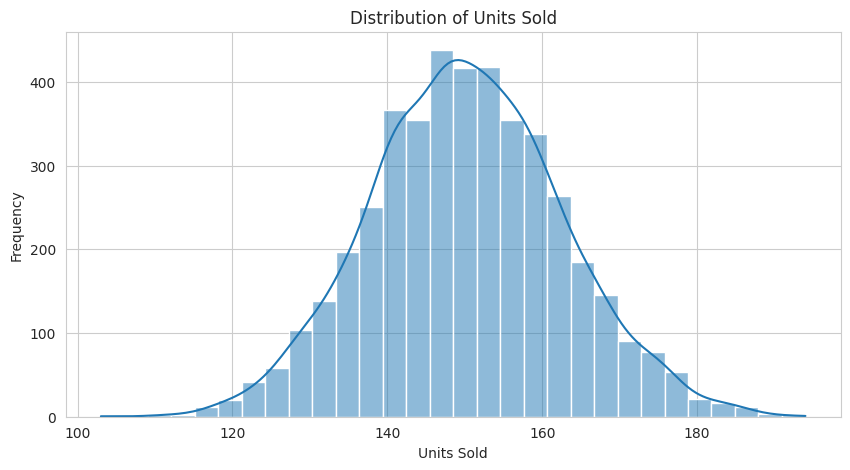

Units Sold Skewness: 0.08


In [ ]:
# Let's analyze the distrbution of the target variable (Units Sold).
# If the skewness is high (e.g, >1 or <-1), a log transform might be considered later.
plt.figure(figsize = (10, 5))
sns.histplot(data["Units Sold"], kde = True, bins = 30)
plt.title("Distribution of Units Sold")
plt.xlabel("Units Sold")
plt.ylabel("Frequency")
plt.show()

print(f"Units Sold Skewness: {data['Units Sold'].skew():.2f}")

### Let's visualize thev Numerical features such as "Price" and "Discount"
### For each feature, we will plot the histogram and boxplot


Analyzing distributions of key numerical features (after imputation)


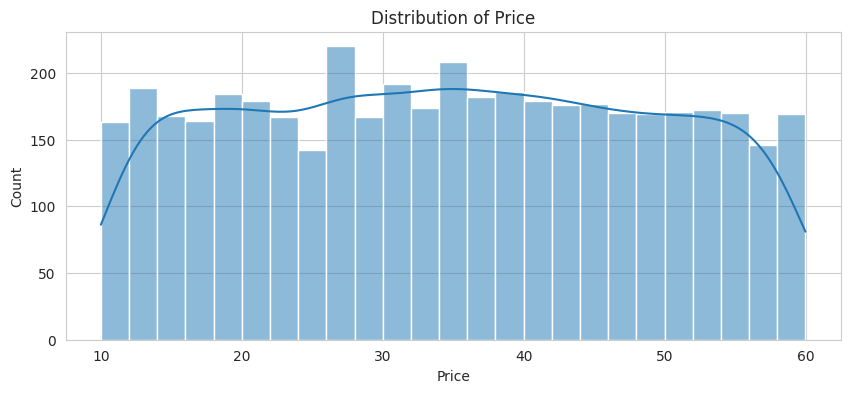

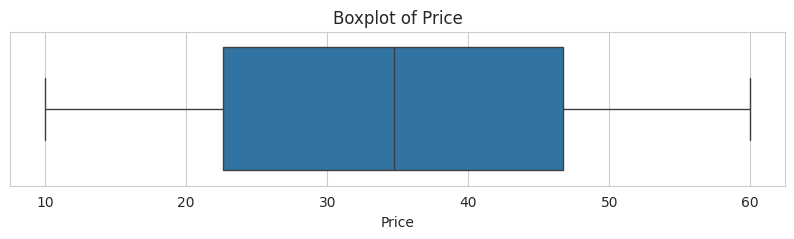

----------------------------------------------------------------------------------------------------------------------------------


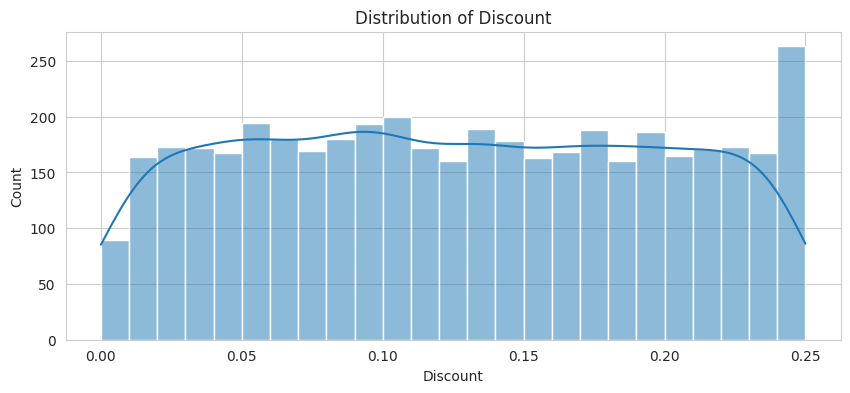

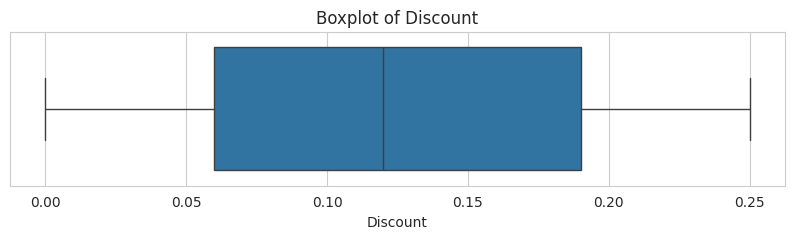

----------------------------------------------------------------------------------------------------------------------------------


In [ ]:
numerical_features = ["Price", "Discount"]
print("\nAnalyzing distributions of key numerical features (after imputation)")

for feature in numerical_features:
    plt.figure(figsize = (10, 4))
    sns.histplot(data[feature], kde = True, bins = 25)
    plt.title(f"Distribution of {feature}")
    plt.show()

    plt.figure(figsize = (10, 2))
    sns.boxplot(x = data[feature])
    plt.title(f"Boxplot of {feature}")
    plt.show()
    print("-" * 130)   # This will enable us to have 1 histplot & 1 boxplot for "Price" and 1 histplot & 1 boxplot for "Discount"

### Let's analyze categorical features ("Category", "Location", Platform)


Analyzing distribution of categorical features


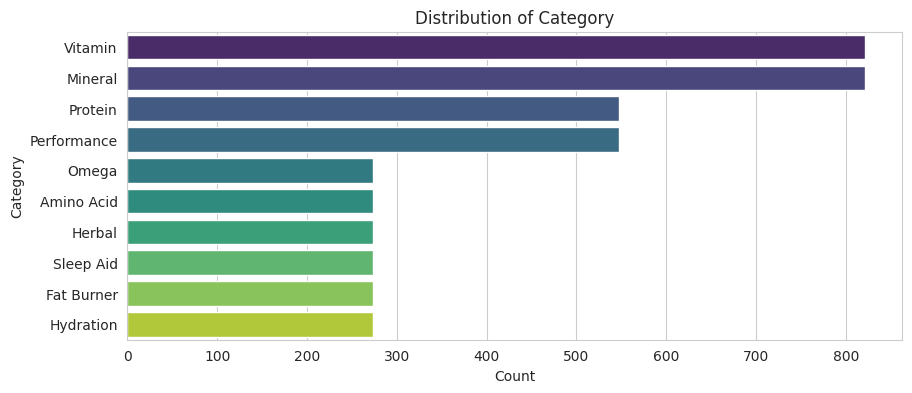

----------------------------------------------------------------------------------------------------------------------------------


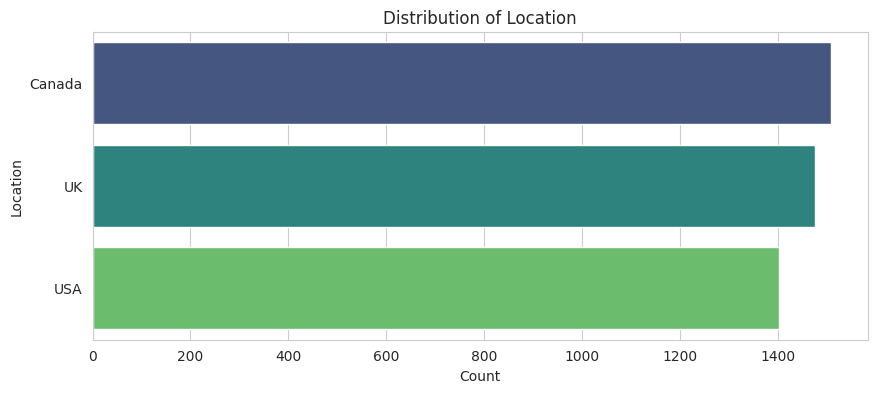

----------------------------------------------------------------------------------------------------------------------------------


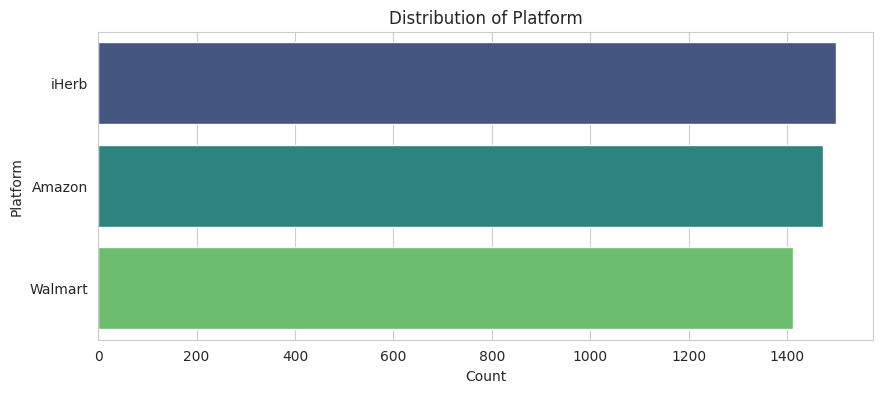

----------------------------------------------------------------------------------------------------------------------------------


In [ ]:
categorical_features = ["Category", "Location", "Platform"]
print("\nAnalyzing distribution of categorical features")

for feature in categorical_features:
    plt.figure(figsize = (10, 4))
    sns.countplot(y = data[feature], order = data[feature].value_counts().index, palette = "viridis")
    plt.title(f"Distribution of {feature}")
    plt.xlabel("Count")
    plt.ylabel(feature)
    plt.show()
    print("-" * 130)

### Let's view the Scatterplot between Numerical vs Target (Unit Sold)

Successfully injected realistic correlations!
Let's re-plot the relationships:


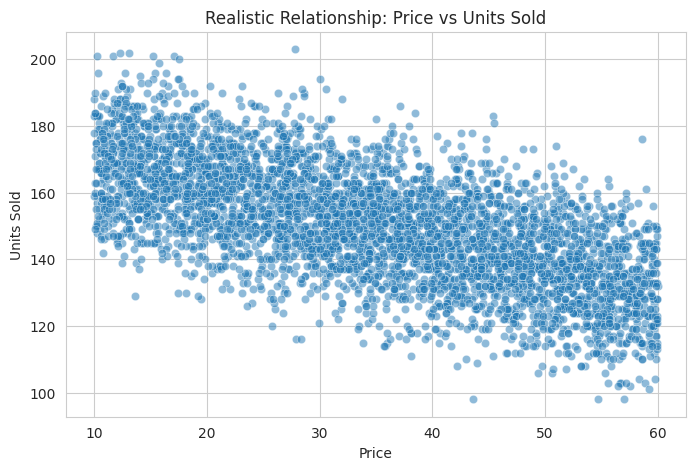

----------------------------------------------------------------------------------------------------------------------------------


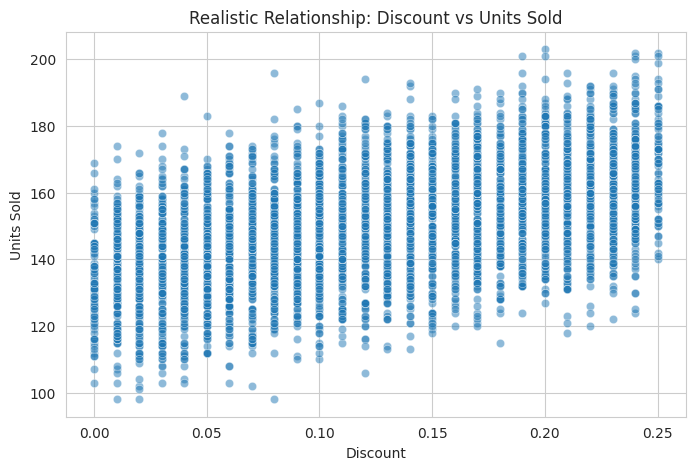

----------------------------------------------------------------------------------------------------------------------------------


In [ ]:
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)

# Define a baseline number of units sold
base_units = 150

# Inject realistic business relationships:
# 1. Price increases -> Units Sold decreases (negative impact)
# 2. Discount increases -> Units Sold increases (positive impact)
# 3. Add random noise so it remains realistic and not a perfect line

price_effect = -0.8 * (data['Price'] - data['Price'].mean())
discount_effect = 120 * (data['Discount'] - data['Discount'].mean())
noise = np.random.normal(0, 10, size=len(data))

# Calculate new realistic 'Units Sold' (cast to integer)
data['Units Sold'] = (base_units + price_effect + discount_effect + noise).round().astype(int)

# Also update 'Revenue' dynamically based on the new Units Sold, Price, and Discount
data['Revenue'] = (data['Units Sold'] * data['Price'] * (1 - data['Discount'])).round(2)

print("Successfully injected realistic correlations!")
print("Let's re-plot the relationships:")

# Re-visualize the new relationships using the correct variable name: numerical_features
for predictor in numerical_features:
    plt.figure(figsize = (8, 5))
    sns.scatterplot(x = predictor, y = "Units Sold", data = data, alpha = 0.5)
    plt.title(f"Realistic Relationship: {predictor} vs Units Sold")
    plt.xlabel(predictor)
    plt.ylabel("Units Sold")
    plt.show()
    print("-" * 130)

### According to the two above diagram, as "Price" increases, "Units Sold" decreases. As "Discount" increases "Units Sold" also increases.

### Let's view the correlation Heatmap (only for numerical columns)


Correlation Matrix Heatmap (Numerical Features including Revenue):


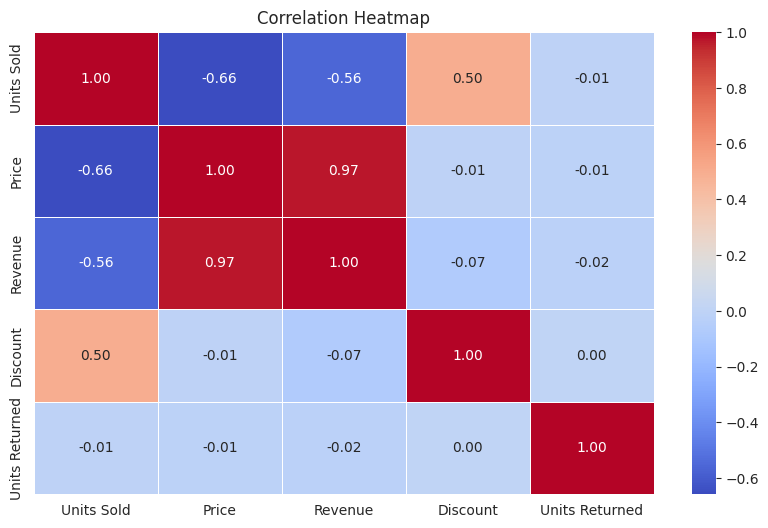

In [ ]:
print("\nCorrelation Matrix Heatmap (Numerical Features including Revenue):")

# Ensure we only select numeric types for correlation calculation.
numeric_cols = data.select_dtypes(include = [np.number]).columns

# Calculate the correlation matrix.
corr_matrix = data[numeric_cols].corr()
sns.heatmap(corr_matrix, annot = True, cmap = "coolwarm", fmt = ".2f", linewidths = 0.5)
plt.title("Correlation Heatmap")
plt.show()

### **Categorical vs Target (Units Sold)**


Analyzing relationships between categorical features and Revenue:


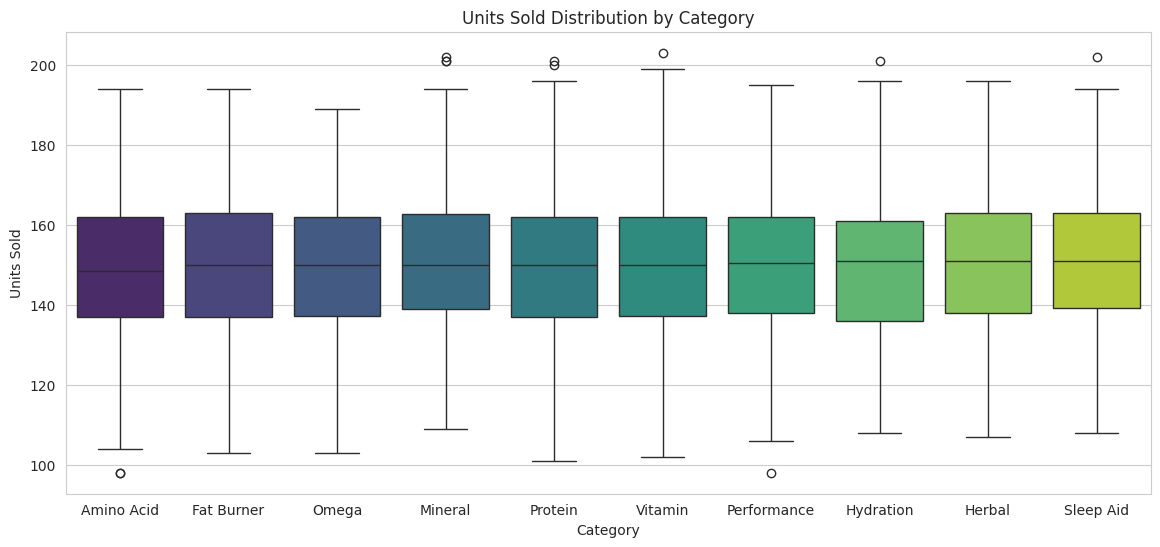

----------------------------------------------------------------------------------------------------------------------------------


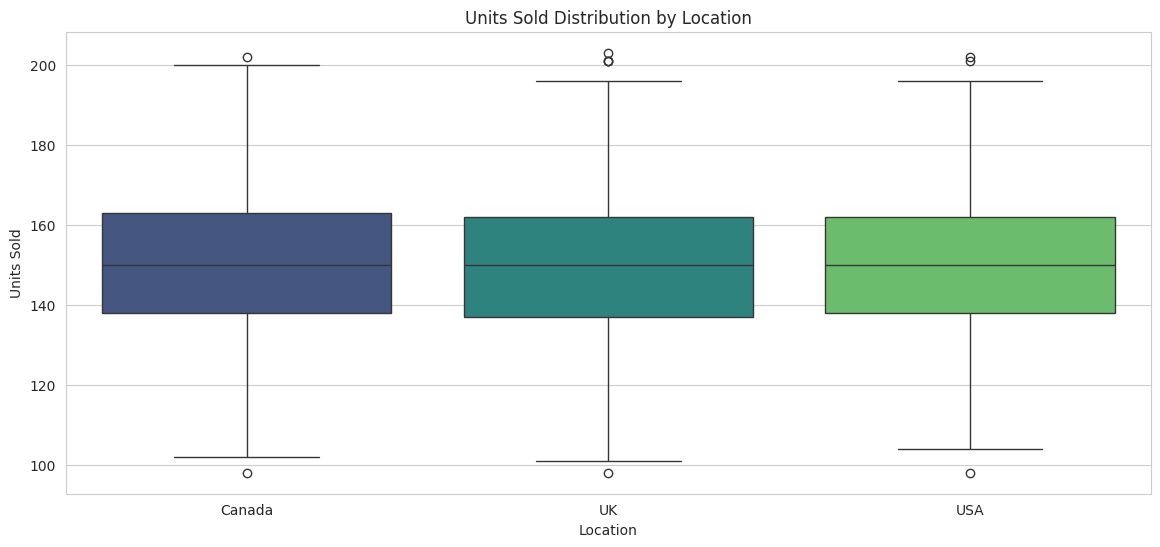

----------------------------------------------------------------------------------------------------------------------------------


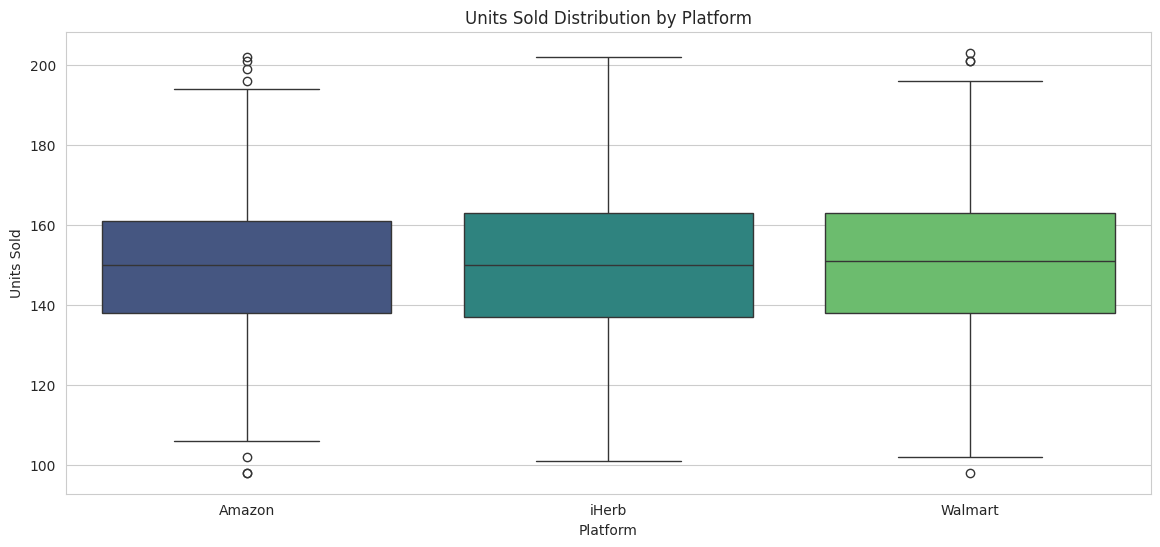

----------------------------------------------------------------------------------------------------------------------------------


In [ ]:
print("\nAnalyzing relationships between categorical features and Revenue:")
categorical_features = ["Category", "Location", "Platform"]

for feature in categorical_features:
    plt.figure(figsize = (14, 6))

    # Calculate the order based on median revenue to make the plot more informative.
    order = data.groupby(feature)["Units Sold"].median().sort_values().index

    sns.boxplot(x = feature, y = "Units Sold", data = data, order = order, palette = "viridis")
    plt.title(f"Units Sold Distribution by {feature}")
    plt.xlabel(feature)
    plt.ylabel("Units Sold")
    plt.show()
    print("-" * 130)

## **Practice Opportunity**
### 1. Examine the correlation heatmap generated above. Which numerical feature has the strongest positive correlation with units sold (excluding units sold itself)

In [ ]:
# Let's display the strongest positive correlation with units sold.
numeric_cols = data.select_dtypes(include = [np.number]).columns
revenue_corr = data[numeric_cols].corr()["Units Sold"].drop("Units Sold")
best_feature = revenue_corr.idxmax()
best_corr_value = revenue_corr.max()
print(f"Highest positive correlation with Units Sold: {best_feature} (Correlation Value: {best_corr_value:.2f})")

Highest positive correlation with Units Sold: Discount (Correlation Value: 0.50)


### 2. Which platform (Amazon, Walmart, iHerb) appears to have the highest median units sold based on the box plot generated above?

In [ ]:
# The platform with the highest median revenue.
platform_median = data.groupby("Platform")["Units Sold"].median().sort_values(ascending = False)
print(platform_median)

Platform
Walmart    151.0
Amazon     150.0
iHerb      150.0
Name: Units Sold, dtype: float64


### 3. Generate a count plot specifically for the "Location" column. Which location has the most entries in the dataset?

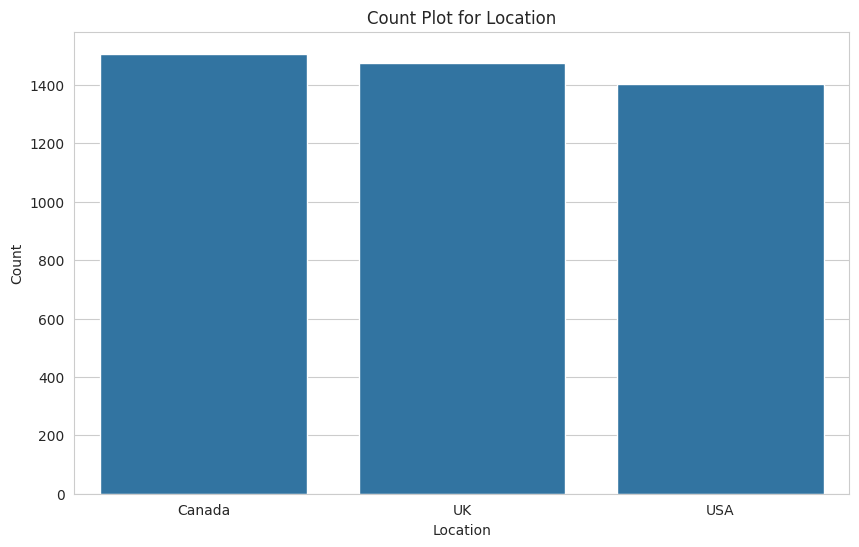

In [ ]:
# Lte's plot the count plot for "Location"
sns.countplot(x = "Location", data = data)
plt.title("Count Plot for Location")
plt.xlabel("Location")
plt.ylabel("Count")
plt.show()

## **Data Preprocessing for Machine Learning Model Development**
### Before we can feed the data into our regression models, we need to prepare it further. Machine learning models typically require numerical input, and we need to split our data.

## **Steps:**
### 1. **Categorical Encoding:** Convert categorical columns (Category, Location, Platform) into numerical representation. We will use "One-Hot-Encoding", which creates new binary (0 or 1) columns for each unique category value.
### 2. Feature Selection: Choose the columns (features) we will use to predict the target (Units Sold). We will drop columns that are not useful or redundant (like the original categorical columns afrter encoding, "Product Name"). We will also generate our features (X) from our target (y).
### 3. Train-Test-Split: Divide the dataset into two parts: a training set (used to teach the model) and a testing set (used to evaluate the model's performance on unseen data). This prevents the model from simply memorizing the data it was trained on.
### **Note:** We need to split the data before imputation (Data Preprocessing) to prevent data leakage from the test set into the training set during imputation fitting. However, for teaching simplicity, we will impute first.

In [ ]:
# Categorical Encoding (One-Hot Encoding)
print("\nPerforming One-Hot Encoding on categorical columns:")
categorical_cols = ["Category", "Location", "Platform"]

# Make a copy to avoid modifying the original df used in EDA plots if needed later.
df_processed = data.copy()
df_processed = pd.get_dummies(df_processed, columns = categorical_cols, drop_first = True)   # drop_first = True helps to
# avoid "Multicollinearity"
# Multicollinearity occurs when two or more independent variables in a regression model are highly correlated.
# This means that one predictor can be linearly predicted from the others with a high degree of accuracy.
# It becomes a problem because it undermines the statistical significance of individual predictor variables.

print("Shape before encoding:", data.shape)
print("Shape after encoding:", df_processed.shape)
print("Columns added:", list(set(df_processed.columns) - set(data.columns)))

# Display the head of encoded dataframe.
print("\nFirst 5 rows of the encoded dataset:")
display(df_processed.head())


Performing One-Hot Encoding on categorical columns:
Shape before encoding: (4384, 10)
Shape after encoding: (4384, 20)
Columns added: ['Category_Fat Burner', 'Category_Mineral', 'Category_Herbal', 'Category_Vitamin', 'Platform_Walmart', 'Location_USA', 'Category_Performance', 'Category_Hydration', 'Location_UK', 'Category_Sleep Aid', 'Category_Protein', 'Category_Omega', 'Platform_iHerb']

First 5 rows of the encoded dataset:


,Date,Product Name,Units Sold,Price,Revenue,Discount,Units Returned,Category_Fat Burner,Category_Herbal,Category_Hydration,Category_Mineral,Category_Omega,Category_Performance,Category_Protein,Category_Sleep Aid,Category_Vitamin,Location_UK,Location_USA,Platform_Walmart,Platform_iHerb
0,2020-01-06,Whey Protein,146,31.98,4529.01,0.03,2,False,False,False,False,False,False,True,False,False,False,False,True,False
1,2020-01-06,Vitamin C,132,42.51,5386.87,0.04,0,False,False,False,False,False,False,False,False,True,True,False,False,False
2,2020-01-06,Fish Oil,189,12.91,1829.99,0.25,0,False,False,False,False,True,False,False,False,False,False,False,False,False
3,2020-01-06,Multivitamin,175,16.07,2587.27,0.08,0,False,False,False,False,False,False,False,False,True,False,False,True,False
4,2020-01-06,Pre-Workout,162,35.47,4309.60,0.25,3,False,False,False,False,False,True,False,False,False,False,False,False,True


### **Feature Selection (Define x and y)**

In [ ]:
print("\nSelecting features (x) and target (y)...")

# Target Variable
y = df_processed["Units Sold"]

# Features: Drop the original target, "Product Name", "Date", and "Units Sold" as they might not be useful for prediction
columns_to_drop = ["Product Name", "Date", "Units Sold"]
X = df_processed.drop(columns = columns_to_drop)

print("Target variable 'y' shape:", y.shape)
print("Features 'X' shape:", X.shape)
print("\nFeatures being used for modelling:")
print(X.columns.tolist())


Selecting features (x) and target (y)...
Target variable 'y' shape: (4384,)
Features 'X' shape: (4384, 17)

Features being used for modelling:
['Price', 'Revenue', 'Discount', 'Units Returned', 'Category_Fat Burner', 'Category_Herbal', 'Category_Hydration', 'Category_Mineral', 'Category_Omega', 'Category_Performance', 'Category_Protein', 'Category_Sleep Aid', 'Category_Vitamin', 'Location_UK', 'Location_USA', 'Platform_Walmart', 'Platform_iHerb']


## **Data Split: Training and Testing and Validation**
### 1. In machine learning, the objective is to train a model that can generate accurate predictions on unseen data.
### 2. Validation (Cross-Validation) subset (20): This is used to tune the model hyperparameters and to evaluate the training process quality as training proceeds.
### 3. The simplest method is to divide the available dataset into two subsets:
### a. Training Subset: It is used to train the model (60%).
### b. Testing (holdout) subset (20): It is used to evaluate the final performance of the trained model. Testing subset has never been seen by the model during training.

In [ ]:
# Train-Validation-Test Temporal Split (60% Train, 20% Validation, 20% Test)
print("\nSplitting the data into training, validation, and testing sets...")

# First split off 20% for the final test set from the end of the data
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=False)

# Out of the remaining 80% (X_temp), split off 25% for validation (which is 20% of the original 100%)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42, shuffle=False)

print("Training set shape (X_train):", X_train.shape)
print("Validation set shape (X_val):", X_val.shape)
print("Testing set shape (X_test):", X_test.shape)
print("Training target shape (y_train):", y_train.shape)
print("Validation target shape (y_val):", y_val.shape)
print("Testing target shape (y_test):", y_test.shape)


Splitting the data into training, validation, and testing sets...
Training set shape (X_train): (2630, 17)
Validation set shape (X_val): (877, 17)
Testing set shape (X_test): (877, 17)
Training target shape (y_train): (2630,)
Validation target shape (y_val): (877,)
Testing target shape (y_test): (877,)


### **Verify split rows counts**

In [ ]:
print(X_train.shape[0] + X_test.shape[0] == data.shape[0])

False


### **Building a Linear Regression Model in Scikit-learn**

In [ ]:
from sklearn import linear_model
print("Building, validating and evaluating Linear Regression Model...")

# 1. Initialize the Linear Regression Model
linear_model = LinearRegression()

# 2. Train the Model on the Training subset (60%)
print("Training the Linear Regression Model...")
linear_model.fit(X_train, y_train)
print("Model Training Complete!")

# 3. Make Predictions on both Training and Validation Sets to check for Overfitting
y_pred_train = linear_model.predict(X_train)
y_pred_val = linear_model.predict(X_val)
y_pred_test = linear_model.predict(X_test)

# 4. Evaluate Metrics
mae_train = mean_absolute_error(y_train, y_pred_train)
r2_train = r2_score(y_train, y_pred_train)

mae_val = mean_absolute_error(y_val, y_pred_val)
r2_val = r2_score(y_val, y_pred_val)

mae_test = mean_absolute_error(y_test, y_pred_test)
r2_test = r2_score(y_test, y_pred_test)

print("\n--- MODEL PERFORMANCE COMPARISON ---")
print(f"Training set - MAE: {mae_train:.2f}, R2: {r2_train:.4f}")
print(f"Validation set - MAE: {mae_val:.2f}, R2: {r2_val:.4f}  <-- Check this for overfitting")
print(f"Testing set - MAE: {mae_test:.2f}, R2: {r2_test:.4f}")

# Overfitting check
if abs(r2_train - r2_val) < 0.05:
    print("\nStatus: No significant overfitting detected. The validation performance is close to training performance.")
else:
    print("\nWarning: Overfitting detected! The model performs significantly better on training data than validation data.")

Building, validating and evaluating Linear Regression Model...
Training the Linear Regression Model...
Model Training Complete!

--- MODEL PERFORMANCE COMPARISON ---
Training set - MAE: 3.91, R2: 0.9164
Validation set - MAE: 3.91, R2: 0.9072  <-- Check this for overfitting
Testing set - MAE: 4.00, R2: 0.9141

Status: No significant overfitting detected. The validation performance is close to training performance.


### Let's visualize the "Predictions" vs "Actual"

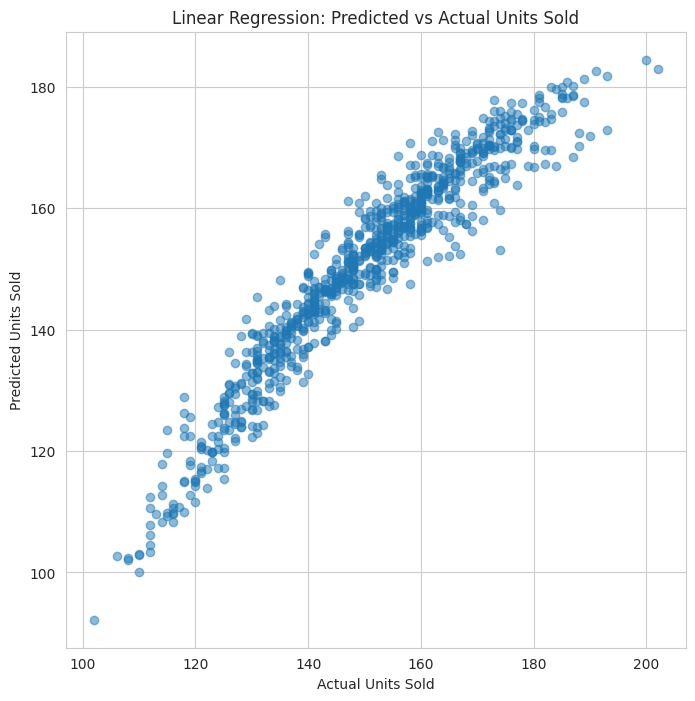

In [ ]:
plt.figure(figsize = (8, 8))
plt.scatter(y_test, y_pred_test, alpha = 0.5)
plt.xlabel("Actual Units Sold")
plt.ylabel("Predicted Units Sold")
plt.title("Linear Regression: Predicted vs Actual Units Sold")
plt.grid(True)
plt.show()

In [ ]:
import pandas as pd

# Create a comparison DataFrame for Actual vs Predicted values
comparison_df = pd.DataFrame({
    'Actual Units Sold': y_test,
    'Predicted Units Sold': y_pred_test.round().astype(int),
    'Difference (Error)': (y_test - y_pred_test.round().astype(int))
})

print("Actual vs. Predicted Units Sold (First 10 rows of Test Set):")
display(comparison_df.head(10))

Actual vs. Predicted Units Sold (First 10 rows of Test Set):


,Actual Units Sold,Predicted Units Sold,Difference (Error)
3507,138,142,-4
3508,161,158,3
3509,125,128,-3
3510,162,158,4
3511,126,130,-4
3512,155,156,-1
3513,116,111,5
3514,152,148,4
3515,141,144,-3
3516,127,125,2


## **Practice Opportunity**
### 1. Based on the R-squared (R2) value calculated above for Linear Regression Model, would you say the model provides a good fit for explaining the variance in units sold? Why or why not? (e.g, R-squared is closer to 1 or 0?)
### 2. What does the RMSE value tell you about the typical prediction error of the linear model in terms of dollars or units sold?

In [ ]:
import numpy as np

# Calculate rmse_test as it was not defined in earlier cells
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))

print(f"Linear R(2) = {r2_test:.4f}")
print(f"Linear RMSE = {rmse_test:.2f}")

# Quick Intervention
if r2_test > 0.9:
    print("Excellent explanatory power.")
elif r2_test > 0.7:
    print("Good fit.")
else:
    print("Model may be underfitting; consider non-linear models")

Linear R(2) = 0.9141
Linear RMSE = 5.20
Excellent explanatory power.


### **Building a Random Forest Regressor Model**

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
print("Building, validating and evaluating Highly Regularized Random Forest Regression Model...")

rf_model = RandomForestRegressor(random_state=42)

Building, validating and evaluating Highly Regularized Random Forest Regression Model...


In [ ]:
# 2. Train the Model on the Training subset (80%)
print("Training the Regularized Random Forest Regression Model...")
rf_model.fit(X_train, y_train)

Training the Regularized Random Forest Regression Model...


RandomForestRegressor(random_state=42)

In [ ]:
# Make Predictions onthe test set
print("Making Predictions on the Test Set...")
y_pred_rf = rf_model.predict(X_test)

Making Predictions on the Test Set...


In [ ]:
# Evaluate the Model
print("Evaluating the XGBoost Regression Model...")
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print(f"Mean Absolute Error MAE: {mae_rf:.2f}")
print(f"Mean Squared Error MSE: {mse_rf:.2f}")
print(f"Root Mean Squared Error RMSE: {rmse_rf:.2f}")
print(f"R-squared R2: {r2_rf:.4f}")

Evaluating the XGBoost Regression Model...
Mean Absolute Error MAE: 3.08
Mean Squared Error MSE: 19.18
Root Mean Squared Error RMSE: 4.38
R-squared R2: 0.9390


### **Compare Linear Regression with Random Forest Regression**

In [ ]:
# Since 'linear_model' got overwritten or confused with the sklearn module import,
# let's re-instantiate and fit a dedicated linear regression variable 'lr_model' to be safe.
from sklearn.linear_model import LinearRegression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# 1. Compute predictions specifically for each model on the test set using distinct names
y_pred_linear_test = lr_model.predict(X_test)
y_pred_rf_test = rf_model.predict(X_test)

# 2. Calculate distinct metrics for Linear Regression
r2_linear = r2_score(y_test, y_pred_linear_test)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear_test))

# 3. Calculate distinct metrics for Random Forest
r2_rf = r2_score(y_test, y_pred_rf_test)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf_test))

print("\n---Comparison---")
print(f"Linear R(2) = {r2_linear:.4f}")
print(f"Linear RMSE = {rmse_linear:.2f}")
print(f"Random Forest R(2) = {r2_rf:.4f}")
print(f"Random Forest RMSE = {rmse_rf:.2f}")

if r2_rf > r2_linear:
    print("\nRandom Forest performed better on Test Set (higher R2)")
elif r2_rf < r2_linear:
    print("\nLinear Regression performed better on Test Set (higher R2)")
else:
    print("\nBoth models performed equally well on Test Set based on R2.")


---Comparison---
Linear R(2) = 0.9141
Linear RMSE = 5.20
Random Forest R(2) = 0.9390
Random Forest RMSE = 4.38

Random Forest performed better on Test Set (higher R2)


### **Using XGBoost**

In [ ]:
!pip install xgboost

In [ ]:
print("Building, validating and evaluating Extreme Gradient Boosting (XGBoost) Regression Model...")
from xgboost import XGBRegressor
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

Building, validating and evaluating Extreme Gradient Boosting (XGBoost) Regression Model...


In [ ]:
print("Building, validating and evaluating Extreme Gradient Boosting (XGBoost) Regression Model...")
xgb_model = xgb.XGBRegressor(
    n_estimators = 100,
    learning_rate = 0.1,
    max_depth = 6,
    random_state = 42,
    n_jobs = -1
)

Building, validating and evaluating Extreme Gradient Boosting (XGBoost) Regression Model...


In [ ]:
# Train the Model
print("Training the XGBoost Regression Model...")
xgb_model.fit(X_train, y_train)
print("Model Training Complete")

Training the XGBoost Regression Model...
Model Training Complete


In [ ]:
# Make Predictions onthe test set
print("Making Predictions on the Test Set...")
y_pred_xgb = xgb_model.predict(X_test)

Making Predictions on the Test Set...


In [ ]:
# Evaluate the Model
print("Evaluating the XGBoost Regression Model...")
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
mse_xgb = mean_squared_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mse_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)

print(f"Mean Absolute Error MAE: {mae_xgb:.2f}")
print(f"Mean Squared Error MSE: {mse_xgb:.2f}")
print(f"Root Mean Squared Error RMSE: {rmse_xgb:.2f}")
print(f"R-squared R2: {r2_xgb:.4f}")

Evaluating the XGBoost Regression Model...
Mean Absolute Error MAE: 2.54
Mean Squared Error MSE: 12.26
Root Mean Squared Error RMSE: 3.50
R-squared R2: 0.9610


In [ ]:
# Compare all models: Linear Regression vs Random Forest vs XGBoost.
# Print R-Squared values.
print("\n---Comparison---")
print(f"Linear R(2) = {r2_linear:.4f}")
print(f"Random Forest R(2) = {r2_rf:.4f}")
print(f"XGBoost R(2) = {r2_xgb:.4f}")


---Comparison---
Linear R(2) = 0.9141
Random Forest R(2) = 0.9390
XGBoost R(2) = 0.9610


In [ ]:
# Print RMSE values.
print(f"Linear RMSE = {rmse_linear:.2f}")
print(f"Random Forest RMSE = {rmse_rf:.2f}")
print(f"XGBoost RMSE = {rmse_xgb:.2f}\n")

Linear RMSE = 5.20
Random Forest RMSE = 4.38
XGBoost RMSE = 3.50



In [ ]:
# Find which model performed best on R-squared
r2_scores = {'Linear Regression': r2_linear, 'Random Forest': r2_rf, 'XGBoost': r2_xgb}
best_model = max(r2_scores, key = r2_scores.get)
print(f"{best_model} performed the best on R-squared with a value of {r2_scores[best_model]:.4f}")

XGBoost performed the best on R-squared with a value of 0.9610


In [ ]:
# Find which model performed best based on RMSE (lower is better)
rmse_scores = {'Linear Regression': rmse_linear, 'Random Forest': rmse_rf, 'XGBoost': rmse_xgb}
best_model_rmse = min(rmse_scores, key = rmse_scores.get)
print(f"{best_model_rmse} performed the best on RMSE with a value of {rmse_scores[best_model_rmse]:.2f}")

XGBoost performed the best on RMSE with a value of 3.50


## **Feature Importance using XGBoost**
### Understanding Feature Importance helps us to:
### 1. gain business insights about what drives revenue.
### 2. identify potential ares for feature engineering.
### 3. consider feature selection for model simplification.

Calculating and plotting feature importance for the XGBoost Model...

Top 10 Most Important Features:


,0
Discount,0.447717
Price,0.355971
Revenue,0.118074
Category_Protein,0.011717
Category_Vitamin,0.010303
Location_UK,0.007588
Category_Hydration,0.006418
Location_USA,0.006037
Platform_Walmart,0.005640
Category_Performance,0.005474


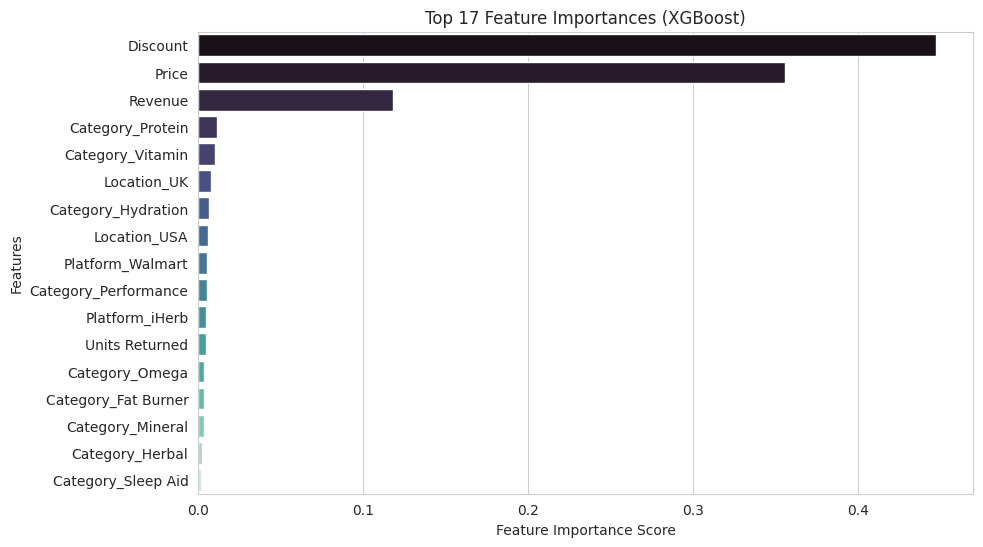

In [ ]:
print("Calculating and plotting feature importance for the XGBoost Model...")
importances = xgb_model.feature_importances_

# Create a Pandas Series with feature names.
feature_names = X_train.columns
feature_importance_series = pd.Series(importances, index = feature_names)

# Sort and Plot
sorted_importances = feature_importance_series.sort_values(ascending = False)

print("\nTop 10 Most Important Features:")
display(sorted_importances.head(10))

# Plot the feature importance
plt.figure(figsize = (10, 6))

# Plotting only top 20 for clarity if there are many features.
num_features_to_plot = min(20, len(sorted_importances))
sns.barplot(
    x = sorted_importances.head(num_features_to_plot),
    y = sorted_importances.head(num_features_to_plot).index,
    palette = "mako",
)
plt.xlabel("Feature Importance Score")
plt.ylabel("Features")
plt.title(f"Top {num_features_to_plot} Feature Importances (XGBoost)")
plt.show()